# Task 2: Adversarial Search -- Tank Battle Game
**Course:** 503043 - Introduction to Artificial Intelligence  
**Topic:** Zero-Sum Game Formulation, Minimax, Alpha-Beta Pruning, and Tactical Heuristic Search

---

## 1. Zero-Sum Game Formulation (Requirement 1 -- Lecture 07 Alignment)

Following the formal adversarial search framework of Russell and Norvig [1] and Lecture 07 (*Adversarial Search*, Slides 4-6 & 9) [3], we formulate the turn-based Tank Battle Game as a finite, deterministic, two-player **Zero-Sum Game** defined by the formal components:
$$\mathcal{G} = \langle S_0, \text{PLAYER}, \text{ACTIONS}, \text{RESULT}, \text{TERMINAL-TEST}, \text{UTILITY} \rangle$$

### 1.1 Initial State ($S_0$) and State Representation ($s \in S$)
Each state $s \in S$ on the $13 \times 13$ Battle City grid ($x \in [0, 12], y \in [0, 12]$) is represented by the tuple:
$$s = \langle t, \text{Tanks}, \text{Bases}, \text{Walls}, \text{Bullets} \rangle$$
At the initial state $S_0$ ($t = 0$):
- **Player 1 (`MAX` from P1's perspective):** Tank at $(2, 10)$ facing $\text{UP}$ with $hp_1 = 6$, Base at $(6, 12)$ with $bhp_1 = 9$.
- **Player 2 (`MIN` from P1's perspective):** Tank at $(10, 2)$ facing $\text{DOWN}$ with $hp_2 = 6$, Base at $(6, 0)$ with $bhp_2 = 9$.
- **Destructible Brick Walls:** $37$ symmetric Battle City brick walls (including Base Fortress shields around $(6, 0)$ and $(6, 12)$, outer-border choke barriers at $(0, 5)$ and $(12, 7)$, side-highway columns, midfield bunkers, and central cross obstacle), each initialized with $whp_i = 3$.
- **Active Projectiles:** $\text{Bullets} = []$ initially; each spawned projectile travels at $\text{BULLET\_SPEED} = 3$ cells per game cycle and inflicts $\text{DAMAGE\_PER\_HIT} = 1$.

| Entity | Initial HP | Damage per Hit | Operational Rule |
| :--- | :---: | :---: | :--- |
| **Tank** | 6 | 1 | Moves 1 cell/turn; game ends immediately if destroyed ($HP \le 0$) |
| **Base** | 9 | 1 | Stationary headquarters; game ends immediately if destroyed ($HP \le 0$) |
| **Wall** | 3 | 1 | Blocks tank movement and bullets; removed immediately when $HP \le 0$ |

### 1.2 Player Function ($\text{PLAYER}(s)$) and Legal Actions ($\text{ACTIONS}(s)$)
- $\text{PLAYER}(s) \in \{\text{MAX}, \text{MIN}\} = \{1, 2\}$ identifies which player acts at ply state $s$ in the alternating two-ply representation of a game cycle.
- $\text{ACTIONS}(s)$ returns the legal discrete actions for the active tank:
$$\text{ACTIONS}(s) = \{\text{FIRE}, \text{MOVE\_UP}, \text{MOVE\_DOWN}, \text{MOVE\_LEFT}, \text{MOVE\_RIGHT}, \text{STAY}\} $$

### 1.3 Transition Model ($\text{RESULT}(s, a)$)
Given state $s$ and joint actions $(a_1, a_2)$, the deterministic transition model processes one full game cycle in three sequential phases:
1. **Tank Movement & Facing Update:** Any tank choosing $\text{MOVE\_}d$ updates its facing direction to $d$ and advances 1 cell to $(x + \Delta x_d, y + \Delta y_d)$ unless blocked by grid boundaries, an alive wall, a base, or the opposing tank.
2. **Projectile Spawning:** Any alive tank choosing $\text{FIRE}$ spawns a bullet at $(x_p, y_p)$ traveling in direction $d_p$.
3. **Cell-by-Cell Bullet Propagation (3 Sub-Steps per Cycle):** Active bullets advance 1 cell at a time across 3 sub-steps. At each 1-cell sub-step:
   - Opposing bullets that move into the same open cell or swap cells head-on ($X \leftrightarrow Y$) collide and cancel each other immediately. If two opposing bullets enter a brick wall cell on the same sub-step, both strike and damage the wall ($HP$ reduced by $1$ per bullet).
   - Any bullet entering a cell with a **Wall**, **Tank**, or **Base** reduces that entity's HP by $1$ and **stops immediately** (removed from the board).

### 1.4 Terminal Test ($\text{TERMINAL-TEST}(s)$) and Utility Function ($\text{UTILITY}(s, p)$)
- $\text{TERMINAL-TEST}(s)$ returns `True` when at least one Tank or Base has $HP \le 0$ (or when the turn limit is reached):
$$\text{TERMINAL-TEST}(s) \iff \exists p \in \{1, 2\}: (hp_p \le 0) \lor (bhp_p \le 0)$$
- $\text{UTILITY}(s, p)$ defines the exact numerical payoff for player $p$ (with opponent $q = 3 - p$ and remaining search depth $d$), strictly satisfying the **Zero-Sum property** $\text{UTILITY}(s, 1) = -\text{UTILITY}(s, 2)$ (Lecture 07, Slides 4-6):
$$\text{UTILITY}(s, p) = \begin{cases} +100000 + 500d + 200(hp_p - hp_q) + 150(bhp_p - bhp_q) & \text{if player } p \text{ wins} \\ -100000 - 500d + 200(hp_p - hp_q) + 150(bhp_p - bhp_q) & \text{if player } q \text{ wins} \\ 200(hp_p - hp_q) + 150(bhp_p - bhp_q) & \text{if draw} \end{cases}$$

### 1.5 Cutoff Test ($\text{CUTOFF-TEST}(s, d)$) and Evaluation Functions ($\text{EVAL}_{\text{basic}}$ vs $\text{EVAL}$)
Following Lecture 07 (Slides 14 & 27-29), because the full game tree has branching factor $b = 6$ per ply ($O(b^m)$ time complexity), searching to terminal states is infeasible in real time. We replace $\text{TERMINAL-TEST}(s)$ with $\text{CUTOFF-TEST}(s, d) \iff \text{TERMINAL-TEST}(s) \lor (d \le 0)$ and distinguish two strictly zero-sum evaluation functions ($\text{EVAL}(s, 1) = -\text{EVAL}(s, 2)$):
1. **Basic Material Payoff (`evaluate_basic` for `MinimaxAgent` and `AlphaBetaAgent` -- Slides 9-26):**
$$\text{EVAL}_{\text{basic}}(s, p) = 300(hp_p - hp_q) + 220(bhp_p - bhp_q) + \Phi_{\text{pos}}(s, p) - \Phi_{\text{pos}}(s, q)$$
2. **Tactical Multi-Feature Heuristic (`evaluate_tactical` / `EVAL(s)` for `HeuristicMinimaxAgent` and `HeuristicAlphaBetaAgent` -- Slides 27-29):**
$$\text{EVAL}(s, p) = 320(hp_p - hp_q) + 240(bhp_p - bhp_q) + \Phi_{\text{bullets}}(s, p) - \Phi_{\text{bullets}}(s, q) + \Phi_{\text{align}}(s, p) - \Phi_{\text{align}}(s, q) + 2(\text{Mob}(s, p) - \text{Mob}(s, q)) + \Phi_{\text{def}}(s, p) - \Phi_{\text{def}}(s, q)$$
where:
- **Material Dominance ($w_{\text{tank}} = 320, w_{\text{base}} = 240$):** Preserving tank and base health strictly dominates positional sub-terms while obeying $\text{Lose} < \text{EVAL}(s) < \text{Win}$ (Lecture 07, Slide 27).
- **3-Cell Projectile Threat & Evasion ($\Phi_{\text{bullets}}$):** Projects all active bullets in 3-cell cycle increments, rewarding 1-cycle offensive tank hits ($+320$, or $-320$ when an enemy bullet is 1 cycle from striking player $p$'s tank) to trigger immediate dodging, rewarding wall-breach shots ($+36$), and penalizing friendly base wall shots ($-60$).
- **Obstacle-Aware Routing, Line-of-Sight, & Base Shield Preservation ($\Phi_{\text{align}}$):** Preserves friendly base shield walls ($+14 \times whp$), prioritizes line-of-sight alignment with the enemy tank ($1.85 \times v_{\text{tank}}$) and enemy base ($1.20 \times v_{\text{base}}$), and minimizes wall-aware shortest-path cost ($4.2 \times \text{cost}_{\text{tank}} + 1.8 \times \text{cost}_{\text{base}}$).


In [1]:
import sys
from pathlib import Path
import time

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "Task2" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from Task2.tank_game_engine import TankGameEngine, Action

engine = TankGameEngine()
init_state = engine.reset()

t0 = time.perf_counter()
for _ in range(5000):
    _ = engine.clone()
clone_rate = int(5000 / max(1e-6, time.perf_counter() - t0))

sim_engine = TankGameEngine()
after_shot, sub_ticks = sim_engine.step(Action.FIRE, Action.STAY)
wall_2_7_hp = next((w["hp"] for w in after_shot["walls"] if w["x"] == 2 and w["y"] == 7), 0)

print(f"Initial Grid Size: {init_state['grid_size']}")
print(f"Player 1 Tank: {init_state['tanks'][1]} | Base: {init_state['bases'][1]}")
print(f"Player 2 Tank: {init_state['tanks'][2]} | Base: {init_state['bases'][2]}")
print(f"Initial Destructible Walls: {len(init_state['walls'])} walls (HP=3 each)")
print("Bullet Sub-Tick Trajectory on FIRE from (2, 10) facing UP:")
print(f"  Sub-tick 1 bullet pos: ({sub_ticks[0]['bullets'][0]['x']}, {sub_ticks[0]['bullets'][0]['y']})")
print(f"  Sub-tick 2 bullet pos: ({sub_ticks[1]['bullets'][0]['x']}, {sub_ticks[1]['bullets'][0]['y']})")
print(f"  Sub-tick 3 impact: struck wall at (2, 7), reducing wall HP to {wall_2_7_hp} (remaining active bullets: {len(after_shot['bullets'])})")
print(f"Engine Clone Throughput: ~{clone_rate:,} clones/second")


Initial Grid Size: (13, 13)
Player 1 Tank: {'x': 2, 'y': 10, 'dir': 'UP', 'hp': 6, 'alive': True} | Base: {'x': 6, 'y': 12, 'hp': 9, 'alive': True}
Player 2 Tank: {'x': 10, 'y': 2, 'dir': 'DOWN', 'hp': 6, 'alive': True} | Base: {'x': 6, 'y': 0, 'hp': 9, 'alive': True}
Initial Destructible Walls: 37 walls (HP=3 each)
Bullet Sub-Tick Trajectory on FIRE from (2, 10) facing UP:
  Sub-tick 1 bullet pos: (2, 9)
  Sub-tick 2 bullet pos: (2, 8)
  Sub-tick 3 impact: struck wall at (2, 7), reducing wall HP to 0 (remaining active bullets: 1)
Engine Clone Throughput: ~891,186 clones/second


---
## 2. Implementation & Comparative Experiments Across the 4 Search Configurations (Requirement 2)

In accordance with Lecture 07 [3], we implement and benchmark four adversarial search configurations:
1. **Minimax Search (`MinimaxAgent` -- Slides 9-14):** Exhaustive depth-bounded recursion (`MINIMAX-DECISION`, `MAX-VALUE`, `MIN-VALUE`) using `evaluate_basic` without pruning ($O(b^m)$ time, $O(bm)$ space).
2. **Alpha-Beta Search (`AlphaBetaAgent` -- Slides 15-26):** Depth-bounded recursion (`ALPHA-BETA-SEARCH`) maintaining $[\alpha, \beta]$ bounds and pruning subtrees whenever $\beta \le \alpha$. Obeys the **Slide 25 Invariant**: *"Pruning does not affect the result"* -- returning the exact same minimax score and action as `MinimaxAgent`.
3. **Heuristic Minimax Search (`HeuristicMinimaxAgent` -- Slides 27-29):** Depth-limited minimax (`H-MINIMAX(s, d)`) using $\text{CUTOFF-TEST}(s, d)$ and the full tactical heuristic evaluation $\text{EVAL}(s)$ (`evaluate_tactical`) without alpha-beta pruning or move ordering.
4. **Heuristic Minimax Search with Alpha-Beta Pruning (`HeuristicAlphaBetaAgent` -- Slides 15-26 & 27-29):** Combines `H-MINIMAX(s, d)` ($\text{EVAL}(s)$) with $\alpha\text{--}\beta$ pruning, **Move Ordering** (`order_actions`), **Killer Move Heuristic** (`_killer_moves`), and **Transposition Table** state caching (`TT_EXACT`, `TT_LOWERBOUND`, `TT_UPPERBOUND`) as specified on Lecture 07 Slide 25 while preserving exact score and action equivalence with `HeuristicMinimaxAgent`.


Depth Scaling Results (standard_arena & open_duel):
Scenario         | Depth | Algorithm                                        |  Time (ms) |  States | Pruning % | TT Hits | Action     |    Score
standard_arena   |     1 | Minimax Search                                   |     0.1538 |       4 |     0.00% |       0 | MOVE_UP    |     0.40
standard_arena   |     1 | Alpha-Beta Search                                |     0.6489 |       4 |     0.00% |       0 | MOVE_UP    |     0.40
standard_arena   |     1 | Heuristic Minimax Search                         |     2.5576 |       4 |     0.00% |       0 | MOVE_UP    |     1.80
standard_arena   |     1 | Heuristic Minimax Search with Alpha-Beta Pruning |     0.4060 |       4 |     0.00% |       0 | MOVE_UP    |     1.80
standard_arena   |     2 | Minimax Search                                   |     0.4246 |      20 |     0.00% |       0 | MOVE_UP    |     0.00
standard_arena   |     2 | Alpha-Beta Search                                | 

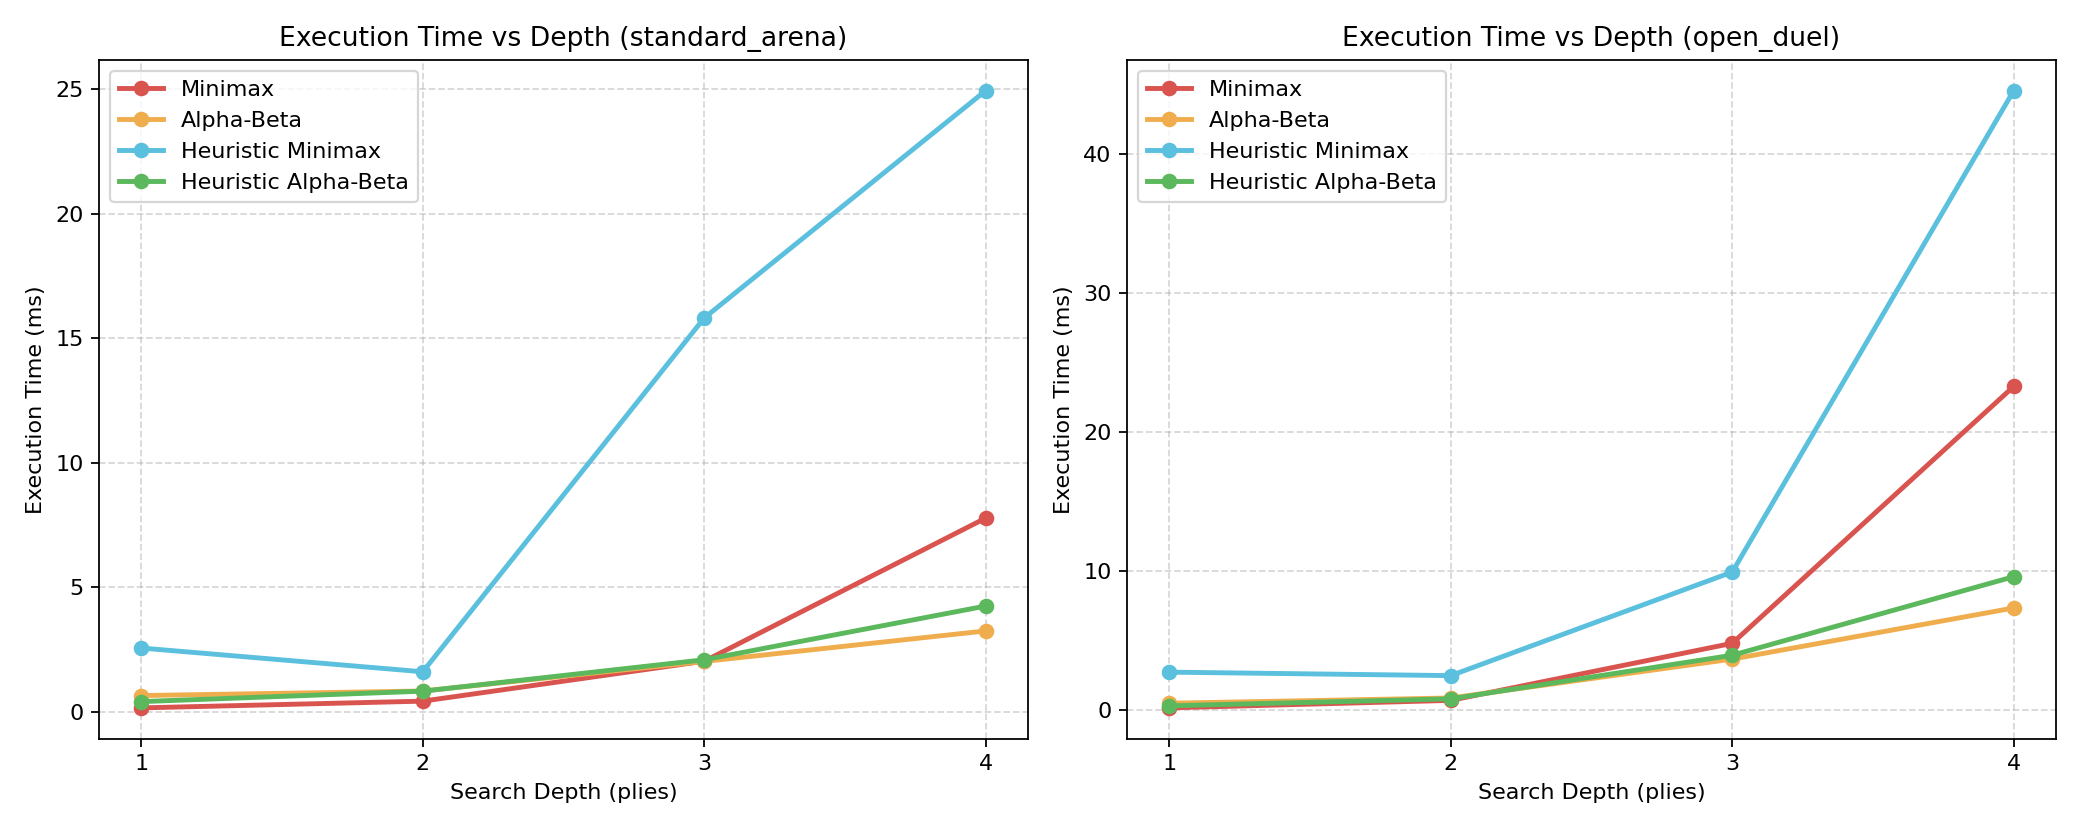

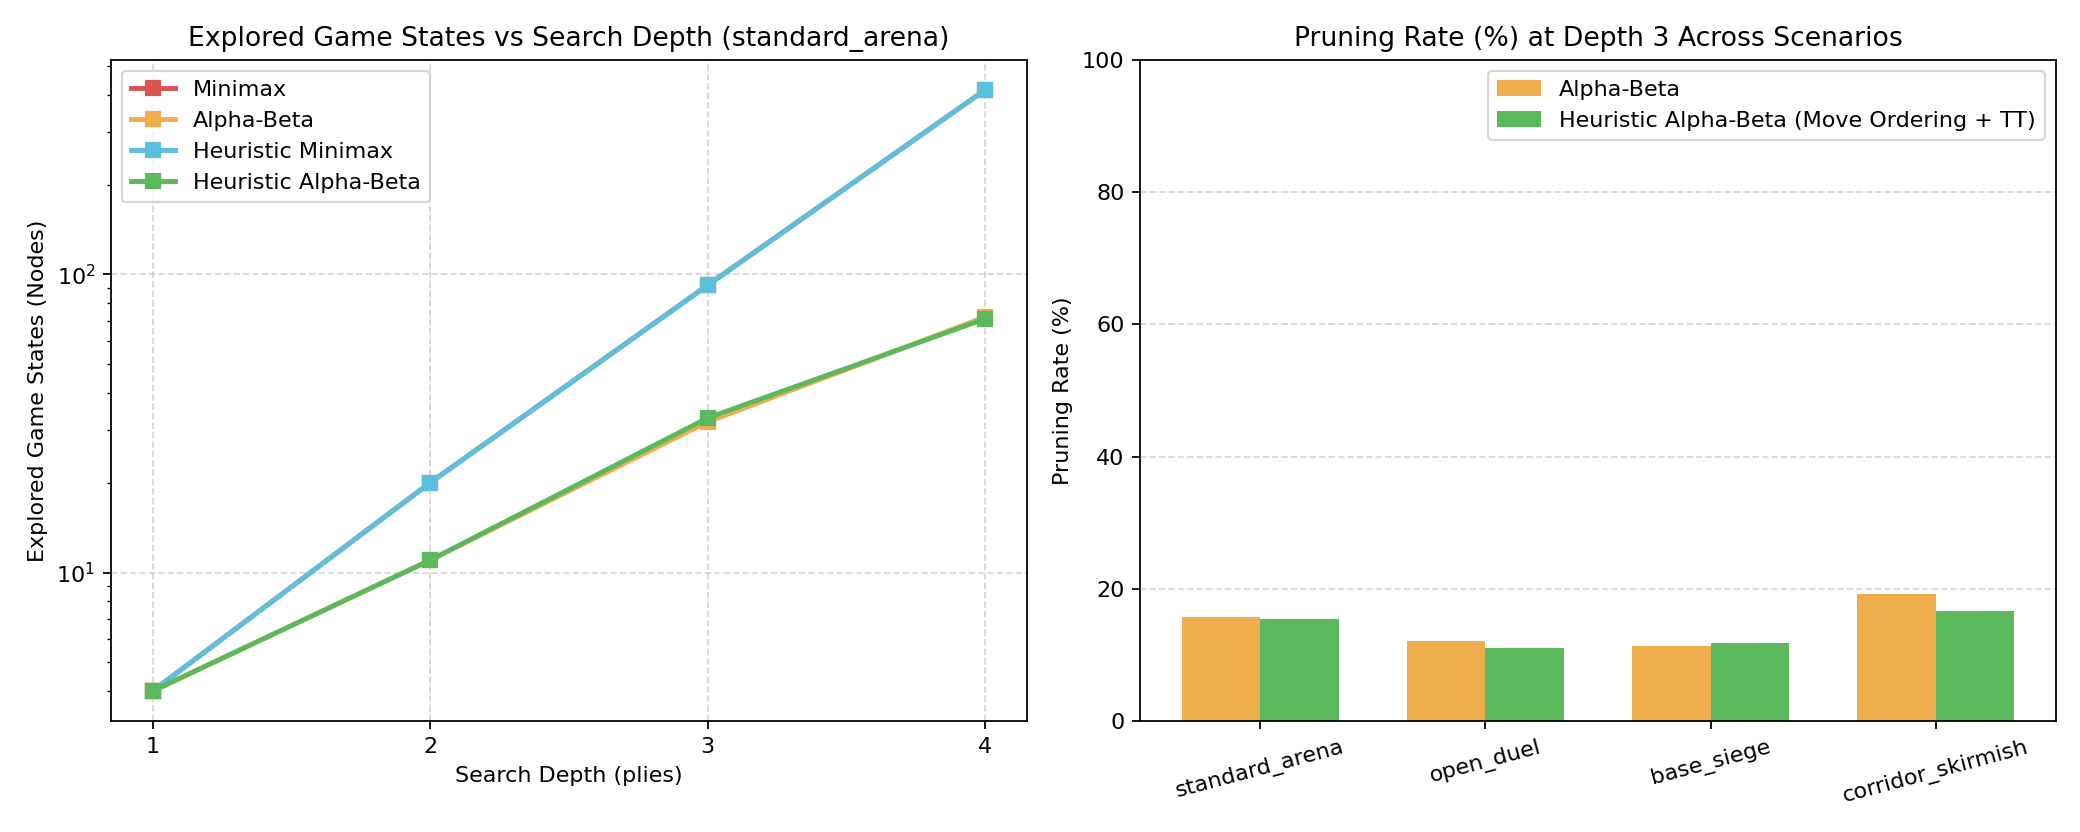

In [2]:
from IPython.display import Image, display
from Task2.experiments.run_experiments import (
    RESULTS_DIR,
    run_depth_scaling_experiments,
    run_scenario_comparison,
)

depth_rows = run_depth_scaling_experiments(depths=[1, 2, 3, 4], scenarios=["standard_arena", "open_duel"])
scenario_rows = run_scenario_comparison(depth=3)

display(Image(filename=str(RESULTS_DIR / "execution_time_comparison.png")))
display(Image(filename=str(RESULTS_DIR / "explored_states_and_pruning.png")))


Head-to-Head Tournament Matchups (Search Depth = 3):
Scenario           | P1 Algorithm                                     | P2 Algorithm                                     | Winner | Turns | P1 HP (T/B) | P2 HP (T/B)
standard_arena     | Heuristic Minimax Search with Alpha-Beta Pruning | Minimax Search                                   | 1      |    26 | 6/6, 9/9 | 6/6, 0/9
standard_arena     | Minimax Search                                   | Heuristic Minimax Search with Alpha-Beta Pruning | 2      |    26 | 6/6, 0/9 | 6/6, 9/9
standard_arena     | Heuristic Minimax Search with Alpha-Beta Pruning | Alpha-Beta Search                                | 1      |    26 | 6/6, 9/9 | 6/6, 0/9
standard_arena     | Alpha-Beta Search                                | Heuristic Minimax Search with Alpha-Beta Pruning | 2      |    26 | 6/6, 0/9 | 6/6, 9/9
standard_arena     | Heuristic Minimax Search                         | Minimax Search                                   | 1      |    26 | 6

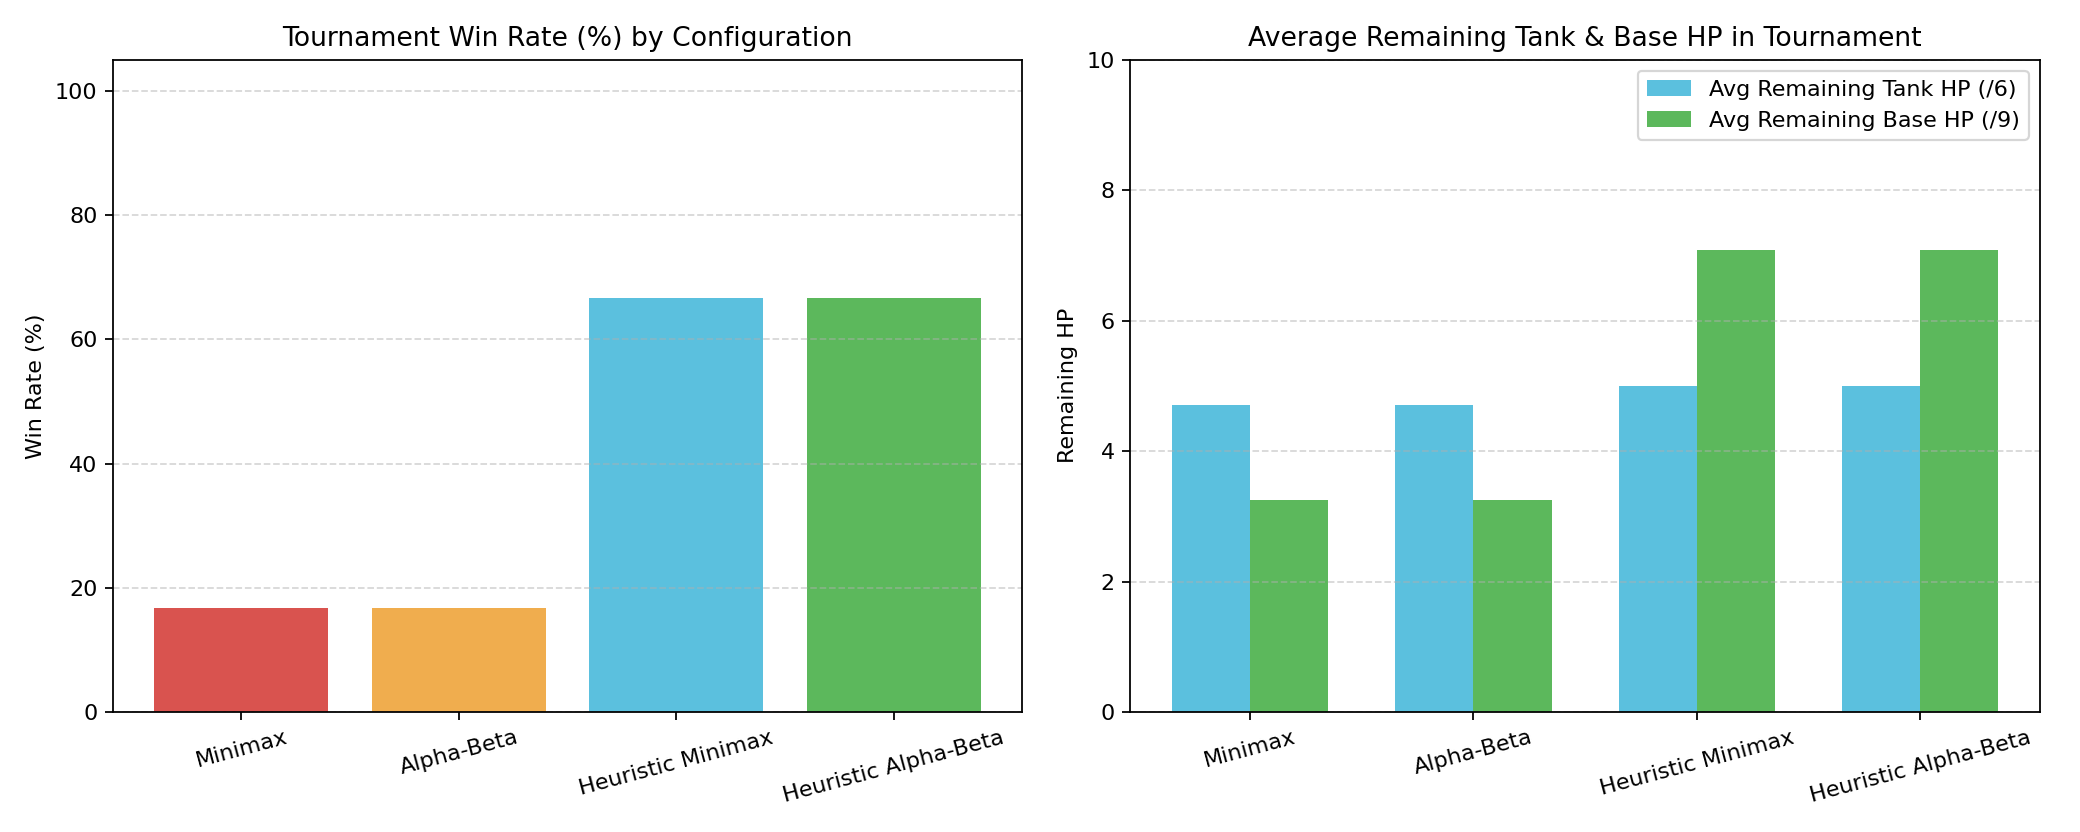

In [3]:
from IPython.display import Image, display
from Task2.experiments.run_experiments import (
    RESULTS_DIR,
    generate_charts,
    run_tournament_experiments,
)

match_rows, summary_rows = run_tournament_experiments(depth=3, max_turns=70)
generate_charts(depth_rows, scenario_rows, summary_rows)
display(Image(filename=str(RESULTS_DIR / "tournament_win_rates_and_hp.png")))


### Key Experimental Findings & Summary Table

| Configuration | Matches | Wins | Win Rate (%) | Avg Tank HP (/6) | Avg Base HP (/9) | Avg Time/Turn (ms) | Avg States/Turn |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Minimax Search** | 24 | 4 | 16.67% | 4.71 | 3.25 | 3.3435 | 182.37 |
| **Alpha-Beta Search** | 24 | 4 | 16.67% | 4.71 | 3.25 | 2.6407 | 74.95 |
| **Heuristic Minimax Search** | 24 | 16 | 66.67% | 5.00 | 7.08 | 7.8451 | 178.72 |
| **Heuristic Minimax Search with Alpha-Beta Pruning** | 24 | 16 | 66.67% | 5.00 | 7.08 | 4.9039 | 60.81 |


1. **Exact Optimality Preservation (Lecture 07, Slide 25 Invariant):** Across all 4 tactical scenarios (`standard_arena`, `open_duel`, `base_siege`, `corridor_skirmish`) and all search depths ($d \in \{1, 2, 3, 4\}$), `AlphaBetaAgent` returns the **exact same `best_score` and `selected_action`** as `MinimaxAgent`, and `HeuristicAlphaBetaAgent` returns the **exact same `best_score` and `selected_action`** as `HeuristicMinimaxAgent`. Consequently, in the symmetric double round-robin tournament, `Minimax Search` and `Alpha-Beta Search` achieve identical win rates (16.67% vs 16.67%) and remaining HP (4.71/6 Tank, 3.25/9 Base), and `Heuristic Minimax Search` and `Heuristic Minimax Search with Alpha-Beta Pruning` achieve identical win rates (66.67% vs 66.67%) and remaining HP (5.00/6 Tank, 7.08/9 Base).
2. **Computational Speedup, Move Ordering, & Transposition Table Caching:** At depth $d = 4$ on `standard_arena`, unpruned `HeuristicMinimaxAgent` explores $416$ states ($24.94\text{ ms}$), whereas `HeuristicAlphaBetaAgent` prunes **$23.66\%$** of the search tree ($17.61\%$ on `open_duel`) with $10$ genuine Transposition Table hits, exploring only $71$ states in **$4.24\text{ ms}$** and reducing average tournament turn time from $7.85\text{ ms}$ to **$4.90\text{ ms}$**.
3. **Tactical Superiority in Head-to-Head Combat:** Across all 4 scenarios (`standard_arena`, `open_duel`, `base_siege`, `corridor_skirmish`) and both P1/P2 sides, the tactical heuristic agents (`HeuristicAlphaBetaAgent` and `HeuristicMinimaxAgent`) defeat the baseline agents in head-to-head combat while navigating the 37-wall Battle City arena without stalling.

---
## 3. PyGame GUI Integration & External Student Group Bot Loader (Requirement 3)

The `Task2` package connects directly to the shared PyGame application (`main.py` and `frontend/`):
- `Task2/tank_game_engine.py` provides `TankGameEngine` and `Action`, exposing `reset() -> dict`, `clone() -> TankGameEngine`, and `step(action_p1, action_p2) -> (state, sub_ticks)` so `frontend/tank_scene.py` animates every 1-cell bullet sub-step and updates tank/base health bars on the 37-wall Battle City arena.
- `Task2/agents.py` defines `BaseTankAgent` along with the four concrete solver classes (`MinimaxAgent`, `AlphaBetaAgent`, `HeuristicMinimaxAgent`, `HeuristicAlphaBetaAgent`) automatically discovered by `frontend/backends.py`.
- External student group `.py` bot files inheriting from `BaseTankAgent` can be imported at runtime via the **Import external bot (.py)** button (or file drag-and-drop) in the PyGame interface or programmatically via `load_external_agent()`.


In [4]:
from pathlib import Path
from Task2.agents import HeuristicAlphaBetaAgent, load_external_agent
from Task2.experiments.run_experiments import play_match

ext_path = Path(ROOT_DIR) / "Task2" / "external_bots" / "sample_group_bot.py"
loaded_classes = load_external_agent(ext_path)
ext_cls = loaded_classes["ExternalGroupBot"]

ext_match = play_match(
    HeuristicAlphaBetaAgent, ext_cls, scenario_name="standard_arena", depth=3, max_turns=60
)

print(f"Loaded External Bot Classes from {ext_path.name}: {list(loaded_classes.keys())}")
print(f"Simulated Match: P1 ({ext_match['p1_algorithm']}) vs P2 ({ext_match['p2_algorithm']})")
print(f"Outcome: Winner = Player {ext_match['winner']} ({ext_match['winner_algorithm']}) in {ext_match['turns_played']} turns")
print(
    f"Remaining HP: P1 Tank={ext_match['p1_remaining_tank_hp']}/6, Base={ext_match['p1_remaining_base_hp']}/9 | "
    f"P2 Tank={ext_match['p2_remaining_tank_hp']}/6, Base={ext_match['p2_remaining_base_hp']}/9"
)
print(
    f"Average Decision Time: P1={ext_match['p1_avg_time_ms']:.4f} ms ({ext_match['p1_avg_explored_states']} states) | "
    f"P2={ext_match['p2_avg_time_ms']:.4f} ms ({ext_match['p2_avg_explored_states']} states)"
)


Loaded External Bot Classes from sample_group_bot.py: ['ExternalGroupBot']
Simulated Match: P1 (Heuristic Minimax Search with Alpha-Beta Pruning) vs P2 (External Group Bot)
Outcome: Winner = Player None (Draw) in 60 turns
Remaining HP: P1 Tank=6/6, Base=9/9 | P2 Tank=6/6, Base=9/9
Average Decision Time: P1=12.2129 ms (88.83 states) | P2=1.5733 ms (17.7 states)


---
## 4. References

[1] S. Russell and P. Norvig, *Artificial Intelligence: A Modern Approach*, 3rd ed. Upper Saddle River, NJ, USA: Prentice Hall, 2009.  
[2] L. H. Bac and T. H. Viet, *Tri tue nhan tao (Artificial Intelligence)*. Ho Chi Minh City, Vietnam: Vietnam National University Ho Chi Minh City Publishing House, 2014.  
[3] N. N. Thao and N. H. Minh, *Lecture 07: Adversarial Search*, Course 503043 - Introduction to Artificial Intelligence, Faculty of Information Technology, Ton Duc Thang University, Ho Chi Minh City, Vietnam, 2020.
